K-Means Centroids:
[[ 7.76333333 91.94       90.66      ]
 [ 2.23333333 61.65666667 52.23333333]
 [ 5.13333333 78.59666667 74.26      ]]

K-Medoids:
[[ 5.3 80.6 74.9]
 [ 2.1 61.1 51.3]
 [ 7.8 95.1 91.8]]
Fakre Alam
SAP ID: 590020990


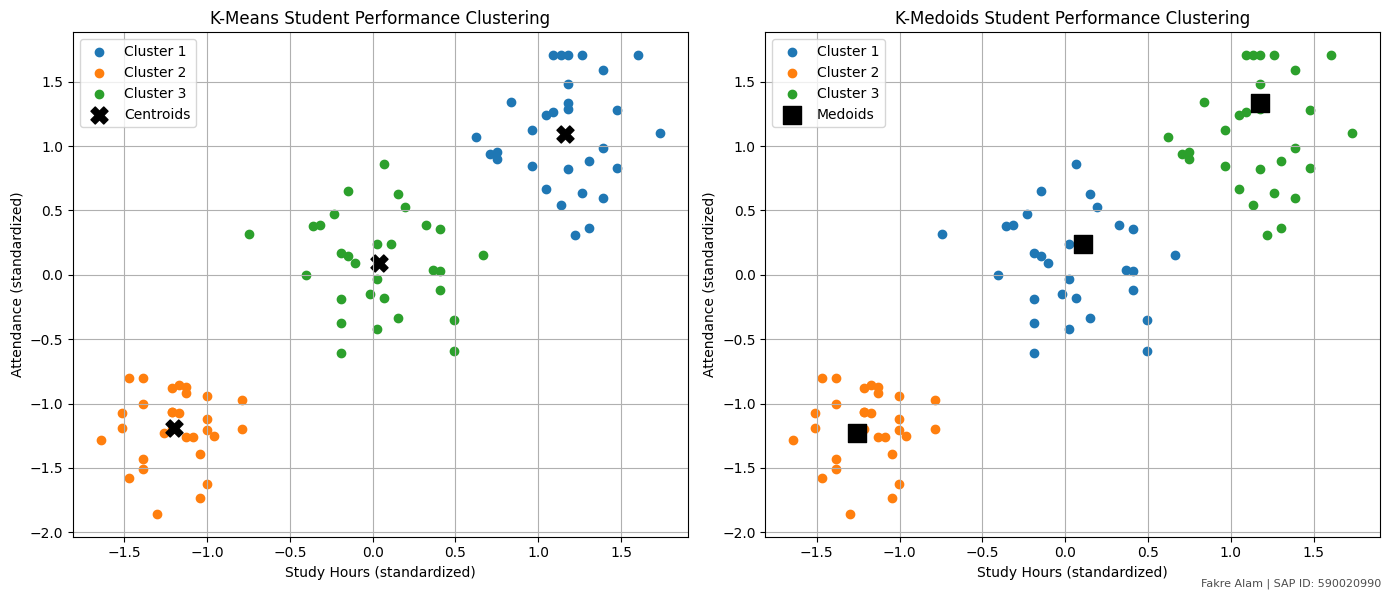

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from sklearn.cluster import KMeans

df = pd.read_csv("student_performance.csv")

features = ["Study_Hours", "Attendance_Percent", "Assignment_Score"]
data = df[features].copy()

scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_clusters = kmeans.fit_predict(scaled_data)
kmeans_centroids = kmeans.cluster_centers_

def k_medoids(data, k, max_iter=100):
    np.random.seed(42)
    medoids = data[np.random.choice(data.shape[0], k, replace=False)]

    for _ in range(max_iter):
        distances = pairwise_distances(data, medoids)
        clusters = np.argmin(distances, axis=1)

        new_medoids = medoids.copy()

        for i in range(k):
            cluster_points = data[clusters == i]

            if len(cluster_points) > 0:
                cluster_distances = pairwise_distances(cluster_points)
                total_distances = cluster_distances.sum(axis=1)
                new_medoids[i] = cluster_points[np.argmin(total_distances)]

        if np.array_equal(medoids, new_medoids):
            break

        medoids = new_medoids

    distances = pairwise_distances(data, medoids)
    clusters = np.argmin(distances, axis=1)

    return medoids, clusters

kmedoids_medoids, kmedoids_clusters = k_medoids(scaled_data, k)

print("K-Means Centroids:")
print(scaler.inverse_transform(kmeans_centroids))

print("\nK-Medoids:")
print(scaler.inverse_transform(kmedoids_medoids))
print("Fakre Alam")
print("SAP ID: 590020990")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)

for i in range(k):
    cluster_data = scaled_data[kmeans_clusters == i]
    plt.scatter(
        cluster_data[:, 0],
        cluster_data[:, 1],
        label=f"Cluster {i+1}"
    )

plt.scatter(
    kmeans_centroids[:, 0],
    kmeans_centroids[:, 1],
    marker="X",
    s=150,
    c="black",
    label="Centroids"
)

plt.title("K-Means Student Performance Clustering")
plt.xlabel("Study Hours (standardized)")
plt.ylabel("Attendance (standardized)")

plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

for i in range(k):
    cluster_data = scaled_data[kmedoids_clusters == i]
    plt.scatter(
        cluster_data[:, 0],
        cluster_data[:, 1],
        label=f"Cluster {i+1}"
    )

plt.scatter(
    kmedoids_medoids[:, 0],
    kmedoids_medoids[:, 1],
    marker="s",
    s=150,
    c="black",
    label="Medoids"
)

plt.title("K-Medoids Student Performance Clustering")
plt.xlabel("Study Hours (standardized)")
plt.ylabel("Attendance (standardized)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.figtext(0.99, 0.01, "Fakre Alam | SAP ID: 590020990",
            ha="right", va="bottom",
            fontsize=8, alpha=0.7)
plt.show()

